# Feature engineering: does a richer feature set help?

**IDX Exchange | Week 6**

Dataset A is the six Week 5 inputs: living area, lot size, bedrooms, bathrooms, city and ZIP. Dataset B adds three size ratios, property age at sale, latitude and longitude, and a school district from a spatial join against the CA School District Areas 2024-25 boundaries. Everything else is held fixed: the Week 5 random forest configuration, the same cleaned sales, the same rows and the same chronological cutoffs. We also run the log-log linear regression on both sets.

With Dataset B the forest's March 2026 validation MdAPE falls from 9.17% to 7.91%, a 1.26-point gain (paired-bootstrap 95% CI 1.09 to 1.47). The gain is between 1.26 and 1.45 points at all four cutoffs, December 2025 through March 2026, and every interval excludes zero. Sales within 20% of the sale price rise from 79.8% to 84.4% in March. The log-log model gains much less (0.18 to 0.60 points).

The ablation shows where the gain comes from. Coordinates do most of the work (1.18 points on their own), age adds about 0.4, and school district helps on its own (0.53) but adds little once coordinates are in. The three ratios do not help. Without them, B scores 7.83% on March, 0.08 points better than full B, so we carry **Dataset B without the ratios** forward to the Week 7 models.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
import avm  # noqa: E402

DATA_DIR = Path("../data/raw")
DISTRICT_SHAPEFILE = Path("../data/external/school_districts_2024_25/DistrictAreas2425.shp")
DISTRICT_CACHE = Path("../data/processed/school_district_by_location.csv")
# Per-sale predictions are licensed CRMLS records, so they stay under data/ (not committed).
MARCH_PREDICTIONS = Path("../data/processed/feature_set_march_predictions.csv")
RESULTS_DIR = Path("../results")
METRICS_PATH = RESULTS_DIR / "feature_set_metrics.csv"
BOOTSTRAP_PATH = RESULTS_DIR / "feature_set_bootstrap.csv"

TARGET = avm.TARGET
VAL_MONTH, TEST_MONTH = avm.TEAM_VAL_MONTH, avm.TEAM_TEST_MONTH
CUTOFFS = avm.TEAM_BACKTEST_MONTHS + [VAL_MONTH]

EXPECTED_FINGERPRINT = "66cab54017ab"  # all 28 files, January 2024 – April 2026
WEEK4_FINGERPRINT = "2ff3877a04bd"     # the 27 files through March 2026
EXPECTED_CLEAN_ROWS = 297_017      # 297,152 Week 4 sales minus 135 re-reported copies
CHOICE_PATH = RESULTS_DIR / "feature_set_choice.json"

# The district join and the experiments are cached; they rebuild when a cache
# file is missing or when these flags are set.
RERUN_DISTRICTS = False
RERUN_EXPERIMENTS = False
N_BOOTSTRAP = 1_000

# The Week 5 random forest, unchanged (notebook 04, FINAL_CONFIGS).
FOREST, LOG_LINEAR = avm.FOREST, avm.LOG_LINEAR
FOREST_PARAMS = {"n_estimators": 200, "max_features": 0.5, "min_samples_leaf": 5, "max_depth": None}
week5 = pd.read_csv(RESULTS_DIR / "model_comparison_metrics.csv", dtype={"month": str})
assert avm.describe_config(FOREST_PARAMS, True) in set(week5.loc[week5["model"] == FOREST, "params"])

A = avm.BASE_FEATURES
FEATURE_SETS = {
    "A": A,
    "A + ratios": A.plus("A + ratios", "ratios"),
    "A + ratios + age": A.plus("A + ratios + age", "ratios", "age"),
    "A + ratios + age + coordinates": A.plus("A + ratios + age + coordinates",
                                             "ratios", "age", "coordinates"),
    "B": avm.EXTENDED_FEATURES,
    "A + age": A.plus("A + age", "age"),
    "A + coordinates": A.plus("A + coordinates", "coordinates"),
    "A + school district": A.plus("A + school district", "school district"),
    "B without ratios": avm.FEATURES_WITHOUT_RATIOS,
}
NO_RATIOS = "B without ratios"
# B without ratios replaces B if its March MdAPE is no more than this much worse.
SIMPLER_SET_TOLERANCE = 0.1
assert FEATURE_SETS["B"] == FEATURE_SETS["A + ratios + age + coordinates"].plus("B", "school district")
CUMULATIVE = ["A", "A + ratios", "A + ratios + age", "A + ratios + age + coordinates", "B"]
SINGLE = ["A + ratios", "A + age", "A + coordinates", "A + school district"]
SET_COLORS = {"A": "#9a9a9a", "B": "#1f7a45"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__,
      "| geopandas", geopandas.__version__)

pandas 3.0.6 | numpy 2.5.3 | sklearn 1.9.1 | geopandas 1.2.0


**Evaluation protocol.** From this notebook on we use the split the team agreed on: backtests at December 2025, January 2026 and February 2026, validation on March 2026, and April 2026 as the shared test month, scored once at the very end (notebook 07). March was the Week 5 test month in notebook 04. It is now the validation month so our numbers line up with the rest of the team. April has never been looked at: its file is fingerprinted with the rest of the pull and then set aside before cleaning.

Each cutoff trains on every month before it, filtered to the 0.5th–99.5th percentile price bounds of those training months. "Filtered" scores sales inside the same frozen bounds; "all" scores every valid sale in the month. Both are reported, with coverage.

## 2. Data

Loading and cleaning reuse `src/avm.py`. The April file is dropped before `clean` runs, and the fingerprint of the remaining 27 files must still match the Week 4 snapshot.

From this notebook on, cleaning also drops **re-reported sales**. Some homes appear twice under the same `ListingKey`, with close dates a few days or weeks apart and the same or nearly the same price. They are one transaction recorded twice, and leaving both in puts a near-copy of a sale on both sides of a train/evaluation cutoff. The rule: when a later record of the same listing closes within 30 days of an earlier kept record, at a price within 2% of it, keep the earliest and drop the later one. It is a fixed rule, not learned from data, so it applies to every month. It is turned on with `avm.clean(raw, drop_rereported=True)` and is off by default, so notebooks 03 and 04 still reproduce their frozen results. It removes 135 of 297,152 sales (0.05%), no more than 15 in any month.

Two new raw fields need plausibility rules. Like the Week 4 rules, these set bad values to missing and never drop a row:

- `YearBuilt` must fall between 1850 and the sale year. Values after the sale year are mostly homes sold before construction finished. They are set to missing rather than given a negative age.
- Latitude and longitude must fall inside a box around California. The excluded values include swapped or sign-flipped coordinates (e.g. longitude +117) and listings marked "outside area (outside CA)".

In [2]:
raw, snapshot, fingerprint = avm.load_raw(DATA_DIR)
assert fingerprint == EXPECTED_FINGERPRINT, f"Data pull changed: {fingerprint}"
used_files = snapshot["file"].str[9:15] < TEST_MONTH
assert avm.snapshot_fingerprint(snapshot.loc[used_files]) == WEEK4_FINGERPRINT
raw = raw.loc[raw["SourceFile"].isin(snapshot.loc[used_files, "file"])]

df, cleaning_steps, set_missing = avm.clean(raw, drop_rereported=True)
assert len(df) == EXPECTED_CLEAN_ROWS, f"Cleaning changed: {len(df):,} rows"
assert df["CloseMonth"].max() == VAL_MONTH
print(f"Files through {VAL_MONTH} (snapshot {WEEK4_FINGERPRINT}): {len(raw):,} raw rows, "
      f"{len(df):,} sales after cleaning")
print(f"April 2026 file ({snapshot.loc[~used_files, 'rows'].sum():,} rows) set aside before cleaning")
display(cleaning_steps.assign(**{c: cleaning_steps[c].map("{:,}".format) for c in ("removed", "rows_left")})
        .set_index("step"))

rereported = cleaning_steps.attrs["rereported"]
by_month = rereported["CloseMonth"].value_counts().reindex(sorted(df["CloseMonth"].unique()), fill_value=0)
print(f"Re-reported copies removed per close month ({len(rereported)} in total, "
      f"at most {by_month.max()} in any month):")
print(", ".join(f"{month_[:4]}-{month_[4:]}: {n}" for month_, n in by_month.items()))

new_fields = pd.DataFrame({
    "Plausibility rule": [f"{avm.EARLIEST_YEAR_BUILT} to the sale year",
                          "Inside a box around California"],
    "Set to missing": [set_missing["YearBuilt"], set_missing["Coordinates"]],
    "Missing after cleaning (%)": [100 * df["YearBuilt"].isna().mean(),
                                   100 * df["Latitude"].isna().mean()],
}, index=["YearBuilt", "Latitude / Longitude"])
display(new_fields.assign(**{"Missing after cleaning (%)":
                             new_fields["Missing after cleaning (%)"].map("{:.2f}".format)}))

Files through 202603 (snapshot 2ff3877a04bd): 591,446 raw rows, 297,017 sales after cleaning
April 2026 file (23,412 rows) set aside before cleaning


,removed,rows_left
step,,
Single-family residences,"294,201","297,245"
Exact duplicates,29,"297,216"
Missing CloseDate,0,"297,216"
Missing or non-positive ClosePrice,3,"297,213"
ClosePrice above $100M,20,"297,193"
CloseDate before listing date,41,"297,152"
"Re-reported sale (same listing, within 30 days and 2% of an earlier close)",135,"297,017"


Re-reported copies removed per close month (135 in total, at most 15 in any month):
2024-01: 0, 2024-02: 0, 2024-03: 0, 2024-04: 0, 2024-05: 11, 2024-06: 13, 2024-07: 4, 2024-08: 10, 2024-09: 3, 2024-10: 4, 2024-11: 4, 2024-12: 15, 2025-01: 5, 2025-02: 2, 2025-03: 5, 2025-04: 4, 2025-05: 5, 2025-06: 8, 2025-07: 6, 2025-08: 2, 2025-09: 6, 2025-10: 4, 2025-11: 5, 2025-12: 11, 2026-01: 4, 2026-02: 2, 2026-03: 2


,Plausibility rule,Set to missing,Missing after cleaning (%)
YearBuilt,1850 to the sale year,36,0.08
Latitude / Longitude,Inside a box around California,72,0.91


## 3. School district join

The boundary file has 937 districts of three types: 345 unified, 516 elementary and 76 high school districts. Outside unified districts, elementary and high school districts overlap, so a home falls in one of each. We give every home one label:

- the unified district's CDS code if the home is in one;
- otherwise its elementary and high school codes joined as "elementary|high".

This keeps the label to the schools a home is actually assigned to and gives each located home exactly one value. We use codes rather than names because 11 district names repeat across counties. Seven polygons in the source file are invalid and are repaired with `make_valid` before the join.

The join is cached per listing location (`ListingKey` plus coordinates) in `data/processed/`. We don't key on `ListingKey` alone because 44 listing keys appear on more than one sale with different coordinates. Missing or out-of-bounds coordinates get no district. The district label is categorical, so it is target-encoded inside the pipeline exactly like city and ZIP.

In [3]:
if RERUN_DISTRICTS:
    DISTRICT_CACHE.unlink(missing_ok=True)
df, newly_joined = avm.attach_school_districts(df, DISTRICT_CACHE, DISTRICT_SHAPEFILE)
assert len(df) == EXPECTED_CLEAN_ROWS
print(f"{newly_joined:,} listing locations joined against the boundaries this run; "
      "the rest came from the cache")

located = df["Latitude"].notna()
matched = df["SchoolDistrict"].notna()
match = pd.DataFrame({"Sales": [len(df), located.sum(), matched.sum(), (located & ~matched).sum()]},
                     index=["All sales", "Usable coordinates", "Matched to a district",
                            "Usable coordinates, outside every district"])
match["Share of all sales (%)"] = (100 * match["Sales"] / len(df)).map("{:.2f}".format)
match["Sales"] = match["Sales"].map("{:,}".format)
display(match)

before_march = df.loc[df["CloseMonth"] < VAL_MONTH, "SchoolDistrict"].value_counts()
print(f"Match rate among sales with usable coordinates: {matched.sum() / located.sum():.2%}")
print("Label type:", df["SchoolDistrictType"].value_counts().to_dict())
print(f"{df['SchoolDistrict'].nunique()} district labels; median {before_march.median():.0f} sales "
      f"per label before March; {(before_march < 20).sum()} labels have fewer than 20")

0 listing locations joined against the boundaries this run; the rest came from the cache


,Sales,Share of all sales (%)
All sales,"297,017",100.00
Usable coordinates,"294,314",99.09
Matched to a district,"294,280",99.08
"Usable coordinates, outside every district",34,0.01


Match rate among sales with usable coordinates: 99.99%
Label type: {'Unified': 220950, 'Elementary + high': 73330}
682 district labels; median 81 sales per label before March; 247 labels have fewer than 20


## 4. Feature sets

| Feature | Group | Definition |
|---|---|---|
| BedBathRatio | ratios | Bedrooms ÷ bathrooms |
| LivingAreaPerBedroom | ratios | Living area ÷ bedrooms |
| LotToLivingAreaRatio | ratios | Lot size ÷ living area |
| AgeAtSale | age | Sale year − year built |
| Latitude, Longitude | coordinates | Property coordinates, CA box enforced |
| SchoolDistrict | school district | Spatial join described above |

Leakage audit, following the IDX best-practices doc: every new feature is a physical or locational fact known before any sale. Age uses the sale year only as the valuation date; in production it is the year of the estimate. List prices, days on market, contract and close fields, and tax amounts stay excluded. `avm.FeatureSet` refuses any of them, and the check below repeats it. We also skip the agent-entered `ElementarySchoolDistrict` and `HighSchoolDistrict` fields in favor of the spatial join, because the join does not depend on what an agent typed.

The engineered columns are computed row by row inside the model pipeline (`avm.add_engineered_features`, the pipeline's first step). Nothing is learned from other rows, and the Week 9 app will get the same transformation by loading the pipeline. Missing values are median-imputed with missing-value indicators, as in Week 5. The table describes sales before March, the training data for the validation cutoff.

In [4]:
B = FEATURE_SETS["B"]
before_march = avm.add_engineered_features(
    avm.model_inputs(df.loc[df["CloseMonth"] < VAL_MONTH], B))
added = [c for c in B.numeric + B.categorical if c not in A.numeric + A.categorical]
summary = pd.DataFrame({
    "Group": [next(g for g, cols in avm.FEATURE_GROUPS.items() if c in cols[0] + cols[1]) for c in added],
    "Missing (%)": [100 * before_march[c].isna().mean() for c in added],
    "Median": [before_march[c].median() if c in B.numeric else np.nan for c in added],
    "1st–99th percentile": [f"{before_march[c].quantile(.01):,.2f} to {before_march[c].quantile(.99):,.2f}"
                            if c in B.numeric else f"{before_march[c].nunique()} labels" for c in added],
}, index=added)
assert not avm.EXCLUDED.intersection(B.inputs)
print("Dataset A:", ", ".join(A.numeric + A.categorical))
print("Dataset B adds:", ", ".join(added))
display(summary.assign(**{"Missing (%)": summary["Missing (%)"].map("{:.2f}".format),
                          "Median": summary["Median"].map(lambda v: "" if pd.isna(v) else f"{v:,.2f}")}))

Dataset A: LivingArea, LotSizeSquareFeet, BedroomsTotal, BathroomsTotalInteger, City, PostalCode
Dataset B adds: BedBathRatio, LivingAreaPerBedroom, LotToLivingAreaRatio, AgeAtSale, Latitude, Longitude, SchoolDistrict


,Group,Missing (%),Median,1st–99th percentile
BedBathRatio,ratios,0.09,1.50,0.67 to 3.00
LivingAreaPerBedroom,ratios,0.15,539.00,"300.00 to 1,247.00"
LotToLivingAreaRatio,ratios,1.87,4.24,1.02 to 141.05
AgeAtSale,age,0.09,49.00,0.00 to 114.00
Latitude,coordinates,0.92,34.09,32.68 to 39.73
Longitude,coordinates,0.92,-118.04,-122.46 to -116.24
SchoolDistrict,school district,0.93,,678 labels


## 5. Controlled experiment: A vs B

The forest is the Week 5 configuration, unchanged: 200 trees, `max_features=0.5`, at least 5 sales per leaf, log-price target. The setup cell checks this against notebook 04's saved results. For the log-log model, the size-like columns (living area, lot size, living area per bedroom, lot-to-living-area ratio) are logged, the other numerics are standardized, and the categoricals are one-hot encoded with rare levels grouped, as in Week 4.

Every model at a cutoff is fitted on the same rows. Each pipeline receives all of Dataset B's raw columns and keeps only those in its own feature set, so the comparison differs in features alone. The paired bootstrap resamples the cutoff's filtered sales 1,000 times (seed 42) and scores both feature sets on the same resample. A negative change means the new set is more accurate.

The last table compares Dataset A with notebook 04. Without the re-reported-sale rule it matches notebook 04 exactly (we checked before turning the rule on). With the rule, the deterministic log-log model moves by at most 0.012 points, which is the effect of the 135 removed sales. The forest moves by up to 0.085 points, because removing rows changes which sales each tree draws. Refitting the Week 5 forest on the January cutoff with only the seed changed (42, 43, 44) gives 9.29%, 9.27% and 9.36%, a spread of 0.084 points. So the forest's shift is within its own seed noise, and none of the comparisons below depend on it.

In [5]:
def factories(month):
    names = list(FEATURE_SETS) if month == VAL_MONTH else ["A", "B", NO_RATIOS]
    out = {f"{FOREST} | {name}": avm.tree_factory(FOREST, FOREST_PARAMS, True, FEATURE_SETS[name])
           for name in names}
    for name in ("A", "B"):
        out[f"{LOG_LINEAR} | {name}"] = lambda fs=FEATURE_SETS[name]: avm.make_linear_model(True, fs)
    return out


def describe(name):
    return ", ".join(FEATURE_SETS[name].numeric + FEATURE_SETS[name].categorical)


def cache_is_current():
    if not (METRICS_PATH.exists() and BOOTSTRAP_PATH.exists() and MARCH_PREDICTIONS.exists()):
        return False
    cached = pd.read_csv(METRICS_PATH)
    return ("clean_rows" in cached and (cached["clean_rows"] == len(df)).all()
            and set(cached["feature_set"]) == set(FEATURE_SETS))


if RERUN_EXPERIMENTS or not cache_is_current():
    metric_rows, bootstrap_rows = [], []
    for month in CUTOFFS:
        # Every model sees the same rows; each pipeline keeps the columns of its own set.
        run = avm.run_cutoff(df, month, factories(month), inputs=FEATURE_SETS["B"])
        for row in avm.metric_records(run, val_month=VAL_MONTH, test_month=TEST_MONTH):
            key = row.pop("model")
            model, name = key.split(" | ")
            metric_rows.append({"model": model, "feature_set": name, **row, "features": describe(name),
                                "fit_seconds": run["results"][key]["fit_seconds"],
                                "clean_rows": len(df)})
        mask = run["in_range"]
        y_true = run["evaluate"].loc[mask, TARGET]
        comparisons = [(key, "A") for key in run["results"] if not key.endswith(" | A")]
        comparisons += [(f"{FOREST} | {NO_RATIOS}", "B")]
        for key, baseline in comparisons:
            model, name = key.split(" | ")
            res, base = run["results"][key], run["results"][f"{model} | {baseline}"]
            diffs = avm.paired_bootstrap_mdape_diff(y_true, res["pred"].loc[mask],
                                                    base["pred"].loc[mask], N_BOOTSTRAP)
            bootstrap_rows.append({
                "month": month, "model": model, "feature_set": name, "baseline": baseline,
                "mdape_change": res["filtered"]["MdAPE_pct"] - base["filtered"]["MdAPE_pct"],
                "ci_low": np.percentile(diffs, 2.5), "ci_high": np.percentile(diffs, 97.5),
                "share_favoring_new": 100 * (diffs < 0).mean()})
        if month == VAL_MONTH:
            MARCH_PREDICTIONS.parent.mkdir(parents=True, exist_ok=True)
            run["evaluate"][[TARGET]].assign(
                in_price_bounds=mask,
                **{f"pred | {key}": res["pred"] for key, res in run["results"].items()}
            ).to_csv(MARCH_PREDICTIONS, index=False)
        fit_minutes = sum(res["fit_seconds"] for res in run["results"].values()) / 60
        print(f"{month}: trained on {run['n_train']:,} sales, {len(run['results'])} models, "
              f"{fit_minutes:.1f} min of fitting")
    pd.DataFrame(metric_rows).to_csv(METRICS_PATH, index=False)
    pd.DataFrame(bootstrap_rows).to_csv(BOOTSTRAP_PATH, index=False)

feature_metrics = pd.read_csv(METRICS_PATH, dtype={"month": str})
feature_bootstrap = pd.read_csv(BOOTSTRAP_PATH, dtype={"month": str})
march_predictions = pd.read_csv(MARCH_PREDICTIONS)
cached_sets = feature_metrics.drop_duplicates("feature_set").set_index("feature_set")["features"]
assert cached_sets.to_dict() == {name: describe(name) for name in FEATURE_SETS}, \
    "Cached runs used different feature sets; set RERUN_EXPERIMENTS = True"
assert sorted(feature_metrics["month"].unique()) == CUTOFFS
print(f"{len(feature_metrics)} metric rows and {len(feature_bootstrap)} bootstrap comparisons loaded")

# Dataset A is the Week 5 setup. Without the re-reported-sale rule it reproduces notebook 04
# exactly; with it, any difference comes from the 135 removed copies.
overlap = feature_metrics.query("feature_set == 'A' and scope == 'filtered'").merge(
    week5.query("scope == 'filtered'"), on=["model", "month"], suffixes=("", "_week5"))
assert len(overlap) == 2 * len(CUTOFFS)
display(pd.DataFrame({
    "Model": overlap["model"], "Month": overlap["month"],
    "Notebook 04 MdAPE (%)": overlap["MdAPE_pct_week5"].map("{:.3f}".format),
    "Here (%)": overlap["MdAPE_pct"].map("{:.3f}".format),
    "Difference (pts)": (overlap["MdAPE_pct"] - overlap["MdAPE_pct_week5"]).map("{:+.3f}".format),
    "N in notebook 04": overlap["N_week5"].map("{:,.0f}".format),
    "N here": overlap["N"].map("{:,.0f}".format),
}).set_index(["Model", "Month"]))

52 metric rows and 22 bootstrap comparisons loaded


,,Notebook 04 MdAPE (%),Here (%),Difference (pts),N in notebook 04,N here
Model,Month,,,,,
Random forest,202512,9.266,9.325,+0.060,"10,330","10,319"
Log-log linear regression,202512,10.079,10.088,+0.009,"10,330","10,319"
Random forest,202601,9.286,9.371,+0.085,"7,388","7,384"
Log-log linear regression,202601,10.603,10.591,-0.012,"7,388","7,384"
Random forest,202602,9.473,9.544,+0.072,"8,869","8,867"
Log-log linear regression,202602,10.594,10.599,+0.004,"8,869","8,867"
Random forest,202603,9.172,9.171,-0.000,"11,420","11,418"
Log-log linear regression,202603,10.035,10.037,+0.002,"11,420","11,418"


**Old vs new feature sets.** Dataset A is the Week 5 feature set and Dataset B adds the Week 6 features. The table covers both models at every cutoff, with the B − A MdAPE change and its 95% interval.

In [6]:
def month_label(month):
    return f"{month[:4]}-{month[4:]}"


def a_vs_b(scope):
    rows = []
    for model in (FOREST, LOG_LINEAR):
        for month in CUTOFFS:
            pick = feature_metrics.query("model == @model and month == @month and scope == @scope")
            a = pick.set_index("feature_set").loc["A"]
            b = pick.set_index("feature_set").loc["B"]
            boot = feature_bootstrap.query(
                "model == @model and month == @month and feature_set == 'B' and baseline == 'A'")
            row = {"Model": model, "Month": month_label(month), "Split": b["split"],
                   "A MdAPE (%)": f"{a['MdAPE_pct']:.2f}", "B MdAPE (%)": f"{b['MdAPE_pct']:.2f}",
                   "B − A (pts)": f"{b['MdAPE_pct'] - a['MdAPE_pct']:+.2f}"}
            if scope == "filtered":
                ci = boot.iloc[0]
                row["95% CI"] = f"{ci['ci_low']:+.2f} to {ci['ci_high']:+.2f}"
            row.update({"A R²": f"{a['R2']:.3f}", "B R²": f"{b['R2']:.3f}",
                        "A within 20% (%)": f"{a['PPE20_pct']:.1f}",
                        "B within 20% (%)": f"{b['PPE20_pct']:.1f}",
                        "N": f"{int(b['N']):,}", "Coverage (%)": f"{100 * b['coverage']:.1f}"})
            rows.append(row)
    return pd.DataFrame(rows).set_index(["Model", "Month"])


print("Filtered scope (sales inside the training-derived price bounds)")
display(a_vs_b("filtered"))
print("All valid sales")
display(a_vs_b("all"))

Filtered scope (sales inside the training-derived price bounds)


Split A MdAPE (%) B MdAPE (%)  \
Model                     Month                                         
Random forest             2025-12    backtest        9.33        7.94   
                          2026-01    backtest        9.37        7.92   
                          2026-02    backtest        9.54        8.16   
                          2026-03  validation        9.17        7.91   
Log-log linear regression 2025-12    backtest       10.09        9.84   
                          2026-01    backtest       10.59        9.99   
                          2026-02    backtest       10.60       10.12   
                          2026-03  validation       10.04        9.86   

                                  B − A (pts)          95% CI   A R²   B R²  \
Model                     Month                                               
Random forest             2025-12       -1.38  -1.57 to -1.20  0.850  0.878   
                          2026-01       -1.45  -1.67 to -1.25  0.851  0.879   
                          2026-02       -1.39  -1.59 to -1.16  0.859  0.883   
                          2026-03       -1.26  -1.47 to -1.09  0.856  0.885   
Log-log linear regression 2025-12       -0.25  -0.41 to -0.13  0.830  0.845   
                          2026-01       -0.60  -0.75 to -0.43  0.821  0.820   
                          2026-02       -0.48  -0.63 to -0.34  0.832  0.837   
                          2026-03       -0.18  -0.34 to -0.08  0.826  0.825   

                                  A within 20% (%) B within 20% (%)       N  \
Model                     Month                                               
Random forest             2025-12             78.6             83.4  10,319   
                          2026-01             78.2             82.6   7,384   
                          2026-02             78.4             83.0   8,867   
                          2026-03             79.8             84.4  11,418   
Log-log linear regression 2025-12             77.9             78.9  10,319   
                          2026-01             76.7             78.0   7,384   
                          2026-02             76.9             78.3   8,867   
                          2026-03             78.7             79.6  11,418   

                                  Coverage (%)  
Model                     Month                 
Random forest             2025-12         98.8  
                          2026-01         98.7  
                          2026-02         99.0  
                          2026-03         98.8  
Log-log linear regression 2025-12         98.8  
                          2026-01         98.7  
                          2026-02         99.0  
                          2026-03         98.8

All valid sales


Split A MdAPE (%) B MdAPE (%)  \
Model                     Month                                         
Random forest             2025-12    backtest        9.46        8.08   
                          2026-01    backtest        9.53        8.07   
                          2026-02    backtest        9.65        8.26   
                          2026-03  validation        9.33        8.03   
Log-log linear regression 2025-12    backtest       10.29        9.96   
                          2026-01    backtest       10.75       10.17   
                          2026-02    backtest       10.73       10.24   
                          2026-03  validation       10.20        9.96   

                                  B − A (pts)   A R²   B R² A within 20% (%)  \
Model                     Month                                                
Random forest             2025-12       -1.38  0.662  0.682             77.7   
                          2026-01       -1.46  0.671  0.689             77.2   
                          2026-02       -1.40  0.684  0.699             77.6   
                          2026-03       -1.30  0.626  0.646             78.9   
Log-log linear regression 2025-12       -0.33  0.706  0.736             77.1   
                          2026-01       -0.58  0.721  0.756             75.7   
                          2026-02       -0.49  0.711  0.734             76.2   
                          2026-03       -0.24  0.698  0.743             77.8   

                                  B within 20% (%)       N Coverage (%)  
Model                     Month                                          
Random forest             2025-12             82.4  10,442         98.8  
                          2026-01             81.5   7,485         98.7  
                          2026-02             82.1   8,956         99.0  
                          2026-03             83.4  11,558         98.8  
Log-log linear regression 2025-12             78.0  10,442         98.8  
                          2026-01             77.0   7,485         98.7  
                          2026-02             77.6   8,956         99.0  
                          2026-03             78.7  11,558         98.8

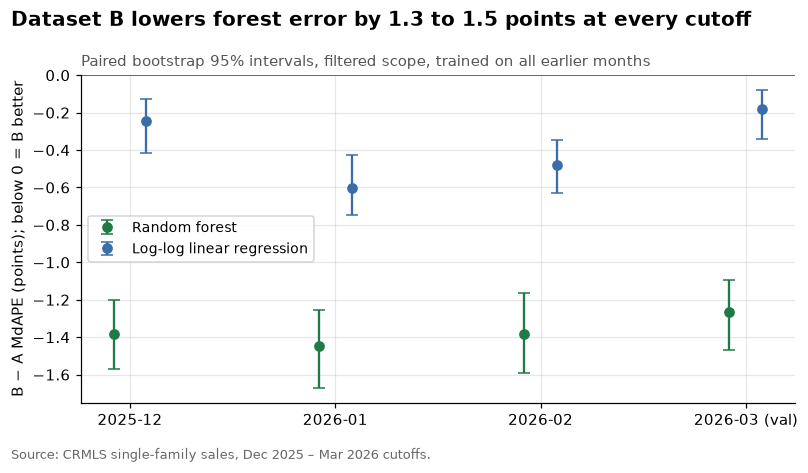

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
offsets = {FOREST: -0.08, LOG_LINEAR: 0.08}
colors = {FOREST: avm.MODEL_COLORS[FOREST], LOG_LINEAR: avm.MODEL_COLORS[LOG_LINEAR]}
for model in (FOREST, LOG_LINEAR):
    rows = feature_bootstrap.query("model == @model and feature_set == 'B' and baseline == 'A'") \
        .set_index("month").loc[CUTOFFS]
    x = np.arange(len(CUTOFFS)) + offsets[model]
    ax.errorbar(x, rows["mdape_change"],
                yerr=[rows["mdape_change"] - rows["ci_low"], rows["ci_high"] - rows["mdape_change"]],
                fmt="o", capsize=4, color=colors[model], label=model)
ax.axhline(0, color="#444444", linewidth=1)
ax.set_xticks(range(len(CUTOFFS)), [month_label(m) + (" (val)" if m == VAL_MONTH else "")
                                    for m in CUTOFFS])
ax.set_ylabel("B − A MdAPE (points); below 0 = B better")
ax.legend(loc="center left", fontsize=9)
avm.finish_chart(fig, ax, "Dataset B lowers forest error by 1.3 to 1.5 points at every cutoff",
                 "Paired bootstrap 95% intervals, filtered scope, trained on all earlier months",
                 "Source: CRMLS single-family sales, Dec 2025 – Mar 2026 cutoffs.")
plt.show()

For the forest the gain is close to constant: 1.38, 1.45, 1.39 and 1.26 points from December to March. All four intervals sit well below zero, roughly 1.1 to 1.7 points. B also raises R² (0.856 to 0.885 in March) and the share within 20% (79.8% to 84.4%). The all-sales scope tells the same story (9.33% to 8.03% in March), so the gain does not depend on the price filter.

The log-log model gains less: 0.18 to 0.60 points, also significant at every cutoff. A linear model can only use latitude and longitude as straight-line trends, so it gets little from coordinates and most of its gain from the one-hot school district.

## 6. Ablation on March validation

Two views on March validation, both with the forest. Cumulative: add the groups one at a time in the order ratios, age, coordinates, school district. One group: add each group to A on its own. The cumulative steps depend on the order, so the one-group rows show what each group can do without the others.

In [8]:
march = feature_metrics.query("month == @VAL_MONTH and model == @FOREST and scope == 'filtered'") \
    .set_index("feature_set")
march_boot = feature_bootstrap.query("month == @VAL_MONTH and model == @FOREST and baseline == 'A'") \
    .set_index("feature_set")
order = CUMULATIVE + [name for name in SINGLE if name not in CUMULATIVE]
ablation = pd.DataFrame({
    "Kind": ["cumulative" if name in CUMULATIVE else "one group" for name in order],
    "MdAPE (%)": march.loc[order, "MdAPE_pct"],
    "Change vs A (pts)": march.loc[order, "MdAPE_pct"] - march.loc["A", "MdAPE_pct"],
}, index=order)
ablation["Step change (pts)"] = np.nan
ablation.loc[CUMULATIVE[1:], "Step change (pts)"] = np.diff(march.loc[CUMULATIVE, "MdAPE_pct"])
ablation["95% CI vs A"] = [""] + [f"{march_boot.loc[n, 'ci_low']:+.2f} to {march_boot.loc[n, 'ci_high']:+.2f}"
                                  for n in order[1:]]
ablation["R²"] = march.loc[order, "R2"]
ablation["Within 20% (%)"] = march.loc[order, "PPE20_pct"]
ablation["Fit time (s)"] = march.loc[order, "fit_seconds"]
display(ablation.assign(**{
    "MdAPE (%)": ablation["MdAPE (%)"].map("{:.2f}".format),
    "Change vs A (pts)": ablation["Change vs A (pts)"].map("{:+.2f}".format),
    "Step change (pts)": ablation["Step change (pts)"].map(lambda v: "" if pd.isna(v) else f"{v:+.2f}"),
    "R²": ablation["R²"].map("{:.3f}".format),
    "Within 20% (%)": ablation["Within 20% (%)"].map("{:.1f}".format),
    "Fit time (s)": ablation["Fit time (s)"].map("{:.0f}".format)}))

,Kind,MdAPE (%),Change vs A (pts),Step change (pts),95% CI vs A,R²,Within 20% (%),Fit time (s)
A,cumulative,9.17,+0.00,,,0.856,79.8,9
A + ratios,cumulative,9.26,+0.09,+0.09,-0.01 to +0.19,0.857,79.7,14
A + ratios + age,cumulative,8.81,-0.37,-0.45,-0.51 to -0.20,0.865,81.0,15
A + ratios + age + coordinates,cumulative,7.98,-1.19,-0.83,-1.38 to -1.03,0.881,84.2,21
B,cumulative,7.91,-1.26,-0.07,-1.47 to -1.09,0.885,84.4,22
A + age,one group,8.79,-0.38,,-0.54 to -0.24,0.864,81.0,11
A + coordinates,one group,8.00,-1.18,,-1.38 to -1.01,0.880,84.2,15
A + school district,one group,8.64,-0.53,,-0.67 to -0.38,0.866,81.8,10


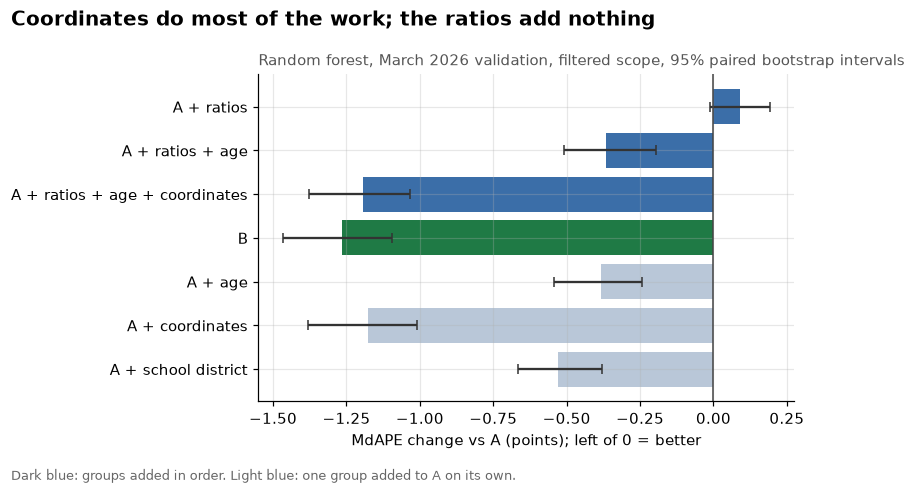

In [9]:
plot_order = order[1:][::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
y = np.arange(len(plot_order))
change = march_boot.loc[plot_order, "mdape_change"]
ax.barh(y, change, color=["#1f7a45" if n == "B" else "#3b6ea8" if n in CUMULATIVE else "#b9c7d8"
                          for n in plot_order])
ax.errorbar(change, y, xerr=[change - march_boot.loc[plot_order, "ci_low"],
                             march_boot.loc[plot_order, "ci_high"] - change],
            fmt="none", ecolor="#333333", capsize=3)
ax.axvline(0, color="#444444", linewidth=1)
ax.set_yticks(y, plot_order)
ax.set_xlabel("MdAPE change vs A (points); left of 0 = better")
avm.finish_chart(fig, ax, "Coordinates do most of the work; the ratios add nothing",
                 "Random forest, March 2026 validation, filtered scope, 95% paired bootstrap intervals",
                 "Dark blue: groups added in order. Light blue: one group added to A on its own.")
plt.show()

- **Ratios:** +0.09 points (CI −0.01 to +0.19), no gain. The forest already has bedrooms, bathrooms, living area and lot size, and can split on combinations of them.
- **Age:** 0.45 points on top of ratios, 0.38 on its own. Year built separates older and newer homes of the same size, which the Week 5 inputs could not do.
- **Coordinates:** the largest gain, 0.83 points as a step and 1.18 on its own. City and ZIP are coarse. Two homes in the same ZIP can differ in price because one is near the coast or a hillside, and coordinates let the forest split on that directly.
- **School district:** 0.53 points on its own, but only 0.07 after coordinates. It carries real location information, and coordinates already contain most of it.

## 7. Dropping the ratios

Since the ratios added nothing, we also run Dataset B without them at every cutoff. The rule was set before looking: if B without ratios is within 0.1 point of B's March MdAPE, we carry the smaller set forward, because three fewer columns means a faster fit, a smaller model, and three fewer inputs to derive in the app. The interval is a paired bootstrap of (without ratios − B) on the same sales.

In [10]:
rows = []
for month in CUTOFFS:
    pick = feature_metrics.query("model == @FOREST and month == @month and scope == 'filtered'") \
        .set_index("feature_set")
    ci = feature_bootstrap.query(
        "model == @FOREST and month == @month and feature_set == @NO_RATIOS and baseline == 'B'").iloc[0]
    rows.append({"Month": month_label(month), "B MdAPE (%)": pick.loc["B", "MdAPE_pct"],
                 "Without ratios (%)": pick.loc[NO_RATIOS, "MdAPE_pct"],
                 "Difference (pts)": pick.loc[NO_RATIOS, "MdAPE_pct"] - pick.loc["B", "MdAPE_pct"],
                 "95% CI": f"{ci['ci_low']:+.2f} to {ci['ci_high']:+.2f}",
                 "B within 20% (%)": pick.loc["B", "PPE20_pct"],
                 "Without ratios within 20% (%)": pick.loc[NO_RATIOS, "PPE20_pct"],
                 "B fit (s)": pick.loc["B", "fit_seconds"],
                 "Without ratios fit (s)": pick.loc[NO_RATIOS, "fit_seconds"]})
no_ratios = pd.DataFrame(rows).set_index("Month")
display(no_ratios.assign(**{
    **{c: no_ratios[c].map("{:.2f}".format) for c in ("B MdAPE (%)", "Without ratios (%)")},
    "Difference (pts)": no_ratios["Difference (pts)"].map("{:+.2f}".format),
    **{c: no_ratios[c].map("{:.1f}".format) for c in ("B within 20% (%)", "Without ratios within 20% (%)")},
    **{c: no_ratios[c].map("{:.0f}".format) for c in ("B fit (s)", "Without ratios fit (s)")}}))

march_gap = no_ratios.loc[month_label(VAL_MONTH), "Difference (pts)"]
chosen = NO_RATIOS if march_gap <= SIMPLER_SET_TOLERANCE else "B"
CHOICE_PATH.write_text(json.dumps({
    "feature_set": chosen,
    "numeric": list(FEATURE_SETS[chosen].numeric),
    "categorical": list(FEATURE_SETS[chosen].categorical),
    "rule": f"B without ratios if its March MdAPE is within {SIMPLER_SET_TOLERANCE} pt of B",
    "march_difference_pts": round(float(march_gap), 4),
}, indent=2) + "\n")
print(f"March difference (without ratios − B): {march_gap:+.2f} points "
      f"(tolerance {SIMPLER_SET_TOLERANCE}) → carry forward: {chosen}")

,B MdAPE (%),Without ratios (%),Difference (pts),95% CI,B within 20% (%),Without ratios within 20% (%),B fit (s),Without ratios fit (s)
Month,,,,,,,,
2025-12,7.94,7.87,-0.07,-0.20 to +0.02,83.4,83.5,19,13
2026-01,7.92,7.96,+0.04,-0.07 to +0.16,82.6,83.0,19,14
2026-02,8.16,8.11,-0.05,-0.17 to +0.06,83.0,83.3,19,15
2026-03,7.91,7.83,-0.08,-0.17 to +0.02,84.4,84.8,22,17


March difference (without ratios − B): -0.08 points (tolerance 0.1) → carry forward: B without ratios


Without the ratios, March MdAPE is 7.83% against 7.91% for full B: 0.08 points *better*, with an interval (−0.17 to +0.02) that includes zero. The backtests agree. The difference is between −0.07 and +0.04 points at each cutoff, every interval includes zero, and the share within 20% is slightly higher without the ratios in all four months. Each forest also fits about a quarter faster.

**From notebook 06 on, the feature set is B without ratios:** living area, lot size, bedrooms, bathrooms, age at sale, latitude, longitude, city, ZIP and school district. The choice and the rule are saved to `results/feature_set_choice.json`, which notebook 06 reads.

## 8. Where the new features help

March validation sales (filtered) split into quintiles of their actual sale price, with the forest's MdAPE in each quintile for A and full B, the two sets in the controlled experiment.

,Price range,A MdAPE (%),B MdAPE (%),B − A (pts),N
band,,,,,
Q1 (lowest),$190K – $565K,8.04,6.88,-1.16,"2,284"
Q2,$566K – $780K,6.94,5.88,-1.06,"2,293"
Q3,"$780K – $1,059K",7.84,6.81,-1.03,"2,276"
Q4,"$1,060K – $1,610K",10.54,8.86,-1.68,"2,283"
Q5 (highest),"$1,611K – $8,175K",13.58,11.87,-1.72,"2,282"


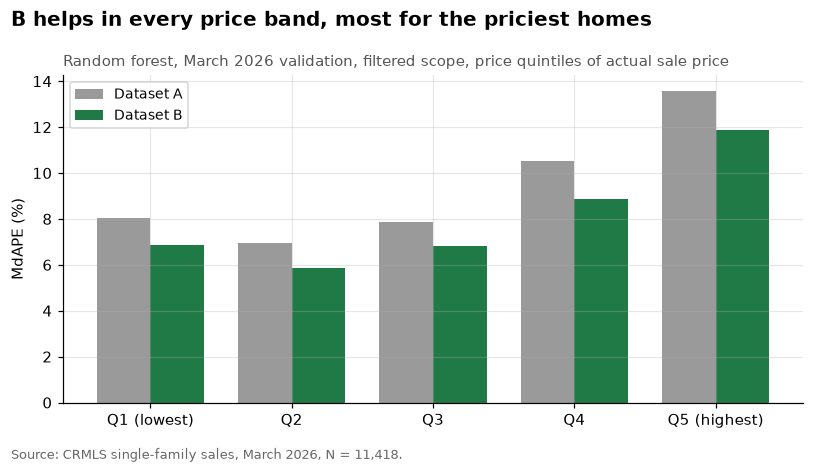

In [11]:
homes = march_predictions.loc[march_predictions["in_price_bounds"]].copy()
homes["band"] = pd.qcut(homes[TARGET], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
ranges = homes.groupby("band", observed=True)[TARGET].agg(["min", "max"])
band_rows = {}
for name in ("A", "B"):
    ape = 100 * (homes[f"pred | {FOREST} | {name}"] - homes[TARGET]).abs() / homes[TARGET]
    band_rows[f"{name} MdAPE (%)"] = ape.groupby(homes["band"], observed=True).median()
bands = pd.DataFrame(band_rows)
bands["B − A (pts)"] = bands["B MdAPE (%)"] - bands["A MdAPE (%)"]
bands.insert(0, "Price range", [f"${lo / 1e3:,.0f}K – ${hi / 1e3:,.0f}K" for lo, hi in ranges.values])
bands["N"] = homes["band"].value_counts().sort_index().map("{:,}".format)
display(bands.assign(**{c: bands[c].map("{:.2f}".format) for c in ["A MdAPE (%)", "B MdAPE (%)"]},
                     **{"B − A (pts)": bands["B − A (pts)"].map("{:+.2f}".format)}))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(bands))
for i, name in enumerate(("A", "B")):
    ax.bar(x + (i - 0.5) * 0.38, bands[f"{name} MdAPE (%)"], width=0.38,
           color=SET_COLORS[name], label=f"Dataset {name}")
ax.set_xticks(x, bands.index)
ax.set_ylabel("MdAPE (%)")
ax.legend(fontsize=9)
avm.finish_chart(fig, ax, "B helps in every price band, most for the priciest homes",
                 "Random forest, March 2026 validation, filtered scope, price quintiles of actual sale price",
                 f"Source: CRMLS single-family sales, March 2026, N = {len(homes):,}.")
plt.show()

B is better in every quintile. The gain is largest for the two most expensive fifths: 1.68 points in Q4 and 1.72 in Q5 (13.58% to 11.87%), against about 1.0 to 1.2 points below. The highest-priced homes vary most within a ZIP code, and coordinates and age help separate them. The top quintile is still the weakest band by a wide margin, which matters for Week 8's error breakdowns.

## 9. Decision and notes

**Carry Dataset B without the ratios forward.** Dataset B lowers the Week 5 forest's MdAPE by 1.26 to 1.45 points at every cutoff, and every interval excludes zero. Dropping the three ratios costs nothing measurable (−0.08 points on March, interval includes zero). The log-log model gains less from B.

Notes for later weeks:

- Notebook 06 (Week 7) tunes LightGBM and XGBoost on B without ratios, with March as validation. The model to beat is the Week 5 forest on the same features (7.83% March MdAPE).
- The re-reported-sale rule also catches the four April sales that repeat a March sale. They are dropped from the test month when notebook 07 cleans with the rule on.
- 247 of the 682 district labels have fewer than 20 sales before March. Target encoding shrinks those toward the overall mean, which is why the district is safe to include even where it is sparse.
- The district boundaries are the 2024-25 version applied to sales from 2024 to 2026. District boundaries rarely move, but a home on a boundary that changed would get the wrong label.
- The district layer also carries enrollment and student-demographic figures. We did not use them: the task was the district itself, and those figures would need their own leakage and timing review.

Files written: `results/feature_set_metrics.csv` (every model × feature set × cutoff × scope), `results/feature_set_bootstrap.csv` (every comparison, with its baseline) and `results/feature_set_choice.json`. Per-sale March predictions and the district cache stay under `data/processed/` because they contain CRMLS records.